In [25]:
import pandas as pd
import requests
from google.colab import files
import io

# The URL for the raw COVID-19 confirmed cases data on GitHub
link = 'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv'

# Send an HTTP GET request to the URL
page = requests.get(link)

# Print the response code to verify success
print(page.status_code)

# Your code's structure for creating a DataFrame
# This time, we read the CSV content directly from the request's text
try:
    df = pd.read_csv(io.StringIO(page.text))
except Exception as e:
    print(f"Error reading CSV: {e}")
    df = pd.DataFrame() # Create an empty DataFrame to prevent further errors

# Print the DataFrame info to confirm it was created
print(df.info())

# Your code's structure for saving to CSV and downloading
df.to_csv('covid19_confirmed_cases.csv', index=False)
print("CSV file 'covid19_confirmed_cases.csv' created.")

# Your code's structure for downloading the file
files.download('covid19_confirmed_cases.csv')
print("File download initiated.")

200
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289 entries, 0 to 288
Columns: 1147 entries, Province/State to 3/9/23
dtypes: float64(2), int64(1143), object(2)
memory usage: 2.5+ MB
None
CSV file 'covid19_confirmed_cases.csv' created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File download initiated.


In [27]:
import pandas as pd
import numpy as np
import statistics as st

# Load the provided CSV file
df = pd.read_csv('covid19_confirmed_cases.csv')

# Melt the DataFrame from wide to long format for easier time-series analysis
df_long = df.melt(
    id_vars=['Province/State', 'Country/Region', 'Lat', 'Long'],
    var_name='Date',
    value_name='Confirmed_Cases'
)

# Check and correct data types
# Convert the 'Date' column to a proper datetime format
df_long['Date'] = pd.to_datetime(df_long['Date'], format='%m/%d/%y', errors='coerce')
# Convert the 'Confirmed_Cases' to a numeric type
df_long['Confirmed_Cases'] = pd.to_numeric(df_long['Confirmed_Cases'])

# Remove duplicates or noise if present
df_long.drop_duplicates(inplace=True)

# Combine data for the same country on the same day to get a total count
df_final = df_long.groupby(['Country/Region', 'Date'])['Confirmed_Cases'].sum().reset_index()

# Print information about the final DataFrame
print("DataFrame Info after preprocessing:")
print(df_final.info())

# Detect and handle missing values
print("\nMissing values after initial cleaning:")
print(df_final.isna().sum())

# We can see that there are no missing values after this initial cleaning
# but if there were, we could use methods like df.dropna() or df.fillna(0) as you suggested.

DataFrame Info after preprocessing:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229743 entries, 0 to 229742
Data columns (total 3 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Country/Region   229743 non-null  object        
 1   Date             229743 non-null  datetime64[ns]
 2   Confirmed_Cases  229743 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 5.3+ MB
None

Missing values after initial cleaning:
Country/Region     0
Date               0
Confirmed_Cases    0
dtype: int64


In [28]:
# Select a single country to demonstrate the process
country_df = df_final[df_final['Country/Region'] == 'India'].copy()

# Find the min and max dates to create a full date range
min_date = country_df['Date'].min()
max_date = country_df['Date'].max()
date_range = pd.date_range(start=min_date, end=max_date)

# Re-index the DataFrame to fill missing dates with NaNs
country_df = country_df.set_index('Date').reindex(date_range).reset_index()
country_df.rename(columns={'index': 'Date'}, inplace=True)
country_df['Country/Region'].fillna('India', inplace=True)

# The 'Confirmed_Cases' column now has NaNs for missing dates.
# We will fill them using backward fill (bfill), as you requested,
# as the number of cases on a missing day would be the same as the next day's count.
country_df['Confirmed_Cases'].fillna(method='bfill', inplace=True)

# Compute a 7-day moving average
country_df['Moving_Average_7_Day'] = country_df['Confirmed_Cases'].rolling(window=7, min_periods=1).mean()

# Print the first and last 10 rows to show the results
print("\nFirst 10 rows of the processed data (for India):")
print(country_df.head(10))

print("\nLast 10 rows of the processed data (for India):")
print(country_df.tail(10))


First 10 rows of the processed data (for India):
        Date Country/Region  Confirmed_Cases  Moving_Average_7_Day
0 2020-01-22          India                0              0.000000
1 2020-01-23          India                0              0.000000
2 2020-01-24          India                0              0.000000
3 2020-01-25          India                0              0.000000
4 2020-01-26          India                0              0.000000
5 2020-01-27          India                0              0.000000
6 2020-01-28          India                0              0.000000
7 2020-01-29          India                0              0.000000
8 2020-01-30          India                1              0.142857
9 2020-01-31          India                1              0.285714

Last 10 rows of the processed data (for India):
           Date Country/Region  Confirmed_Cases  Moving_Average_7_Day
1133 2023-02-28          India         44687837          4.468724e+07
1134 2023-03-01         

/tmp/ipython-input-1022019396.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  country_df['Country/Region'].fillna('India', inplace=True)
/tmp/ipython-input-1022019396.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tr

In [29]:
print("\n--- Descriptive Statistical Analysis ---")

# Overall descriptive statistics
print("\nOverall descriptive statistics for the entire dataset:")
print(df_final['Confirmed_Cases'].describe())

# Statistics for a single country (India)
print("\nDescriptive statistics for Confirmed Cases in India:")
print(country_df['Confirmed_Cases'].describe())

print("\nDescriptive statistics for the 7-Day Moving Average in India:")
print(country_df['Moving_Average_7_Day'].describe())

# Use the statistics module as you requested
print("\nStatistics for 'Confirmed_Cases' in India using the statistics module:")
print('Mean:', st.mean(country_df['Confirmed_Cases']))
print('Median:', st.median(country_df['Confirmed_Cases']))
print('Population Standard Deviation:', st.pstdev(country_df['Confirmed_Cases']))
print('Sample Standard Deviation:', st.stdev(country_df['Confirmed_Cases']))


--- Descriptive Statistical Analysis ---

Overall descriptive statistics for the entire dataset:
count    2.297430e+05
mean     1.379412e+06
std      5.810423e+06
min      0.000000e+00
25%      3.831000e+03
50%      5.293300e+04
75%      4.995925e+05
max      1.038027e+08
Name: Confirmed_Cases, dtype: float64

Descriptive statistics for Confirmed Cases in India:
count    1.143000e+03
mean     2.548654e+07
std      1.759640e+07
min      0.000000e+00
25%      8.290750e+06
50%      3.222551e+07
75%      4.315163e+07
max      4.469074e+07
Name: Confirmed_Cases, dtype: float64

Descriptive statistics for the 7-Day Moving Average in India:
count    1.143000e+03
mean     2.536925e+07
std      1.761621e+07
min      0.000000e+00
25%      8.157041e+06
50%      3.211497e+07
75%      4.314399e+07
max      4.468966e+07
Name: Moving_Average_7_Day, dtype: float64

Statistics for 'Confirmed_Cases' in India using the statistics module:
Mean: 25486543.91426072
Median: 32225513
Population Standard Devia

In [31]:
import pandas as pd
from google.colab import files

# Load the provided CSV file into a DataFrame
df = pd.read_csv('covid19_confirmed_cases.csv')

# --- Data Preprocessing ---

# 1. Melt the DataFrame from a wide to a long format for easier analysis
df_long = df.melt(
    id_vars=['Province/State', 'Country/Region', 'Lat', 'Long'],
    var_name='Date',
    value_name='Confirmed_Cases'
)

# 2. Check and correct data types
df_long['Date'] = pd.to_datetime(df_long['Date'], format='%m/%d/%y', errors='coerce')
df_long['Confirmed_Cases'] = pd.to_numeric(df_long['Confirmed_Cases'])

# 3. Handle missing values
df_long.dropna(subset=['Date', 'Confirmed_Cases'], inplace=True)

# 4. Combine data for the same country on the same day to get a total count
df_final = df_long.groupby(['Country/Region', 'Date'])['Confirmed_Cases'].sum().reset_index()

# 5. Remove any duplicates
df_final.drop_duplicates(inplace=True)

# Save the cleaned and processed data to a new CSV file
cleaned_filename = 'covid19_cleaned_data.csv'
df_final.to_csv(cleaned_filename, index=False)

# Download the file to your computer
try:
    files.download(cleaned_filename)
    print(f"✅ Successfully downloaded {cleaned_filename}")
except Exception as e:
    print(f"❌ Error downloading the file: {e}")
    print("You can download the file manually from the left-side file browser in Colab.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Successfully downloaded covid19_cleaned_data.csv


Generating Bar Graph...


/tmp/ipython-input-4225431965.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Confirmed_Cases', y='Country/Region', data=df_bar, palette='viridis')


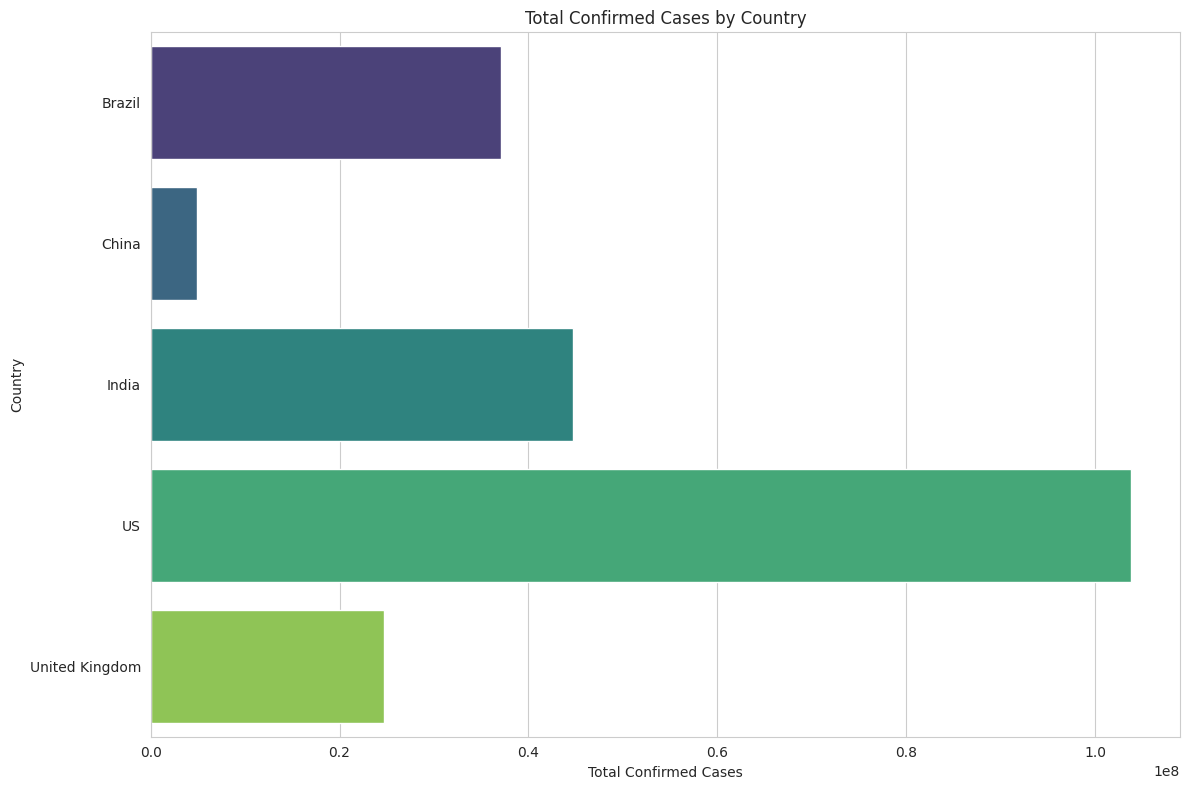


Generating Histogram...


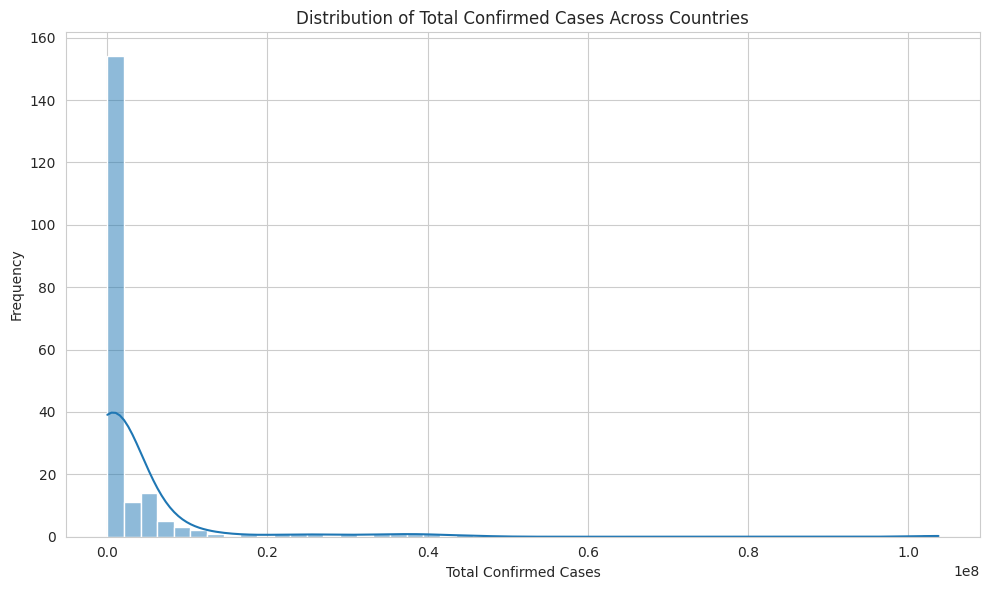


Generating Boxplot...


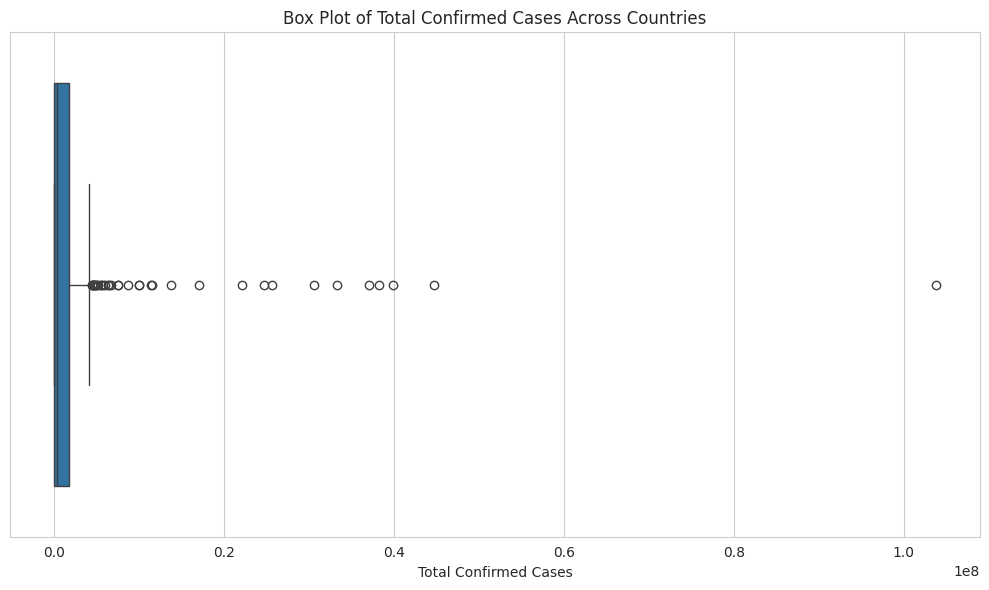


Generating Time-series Plot...


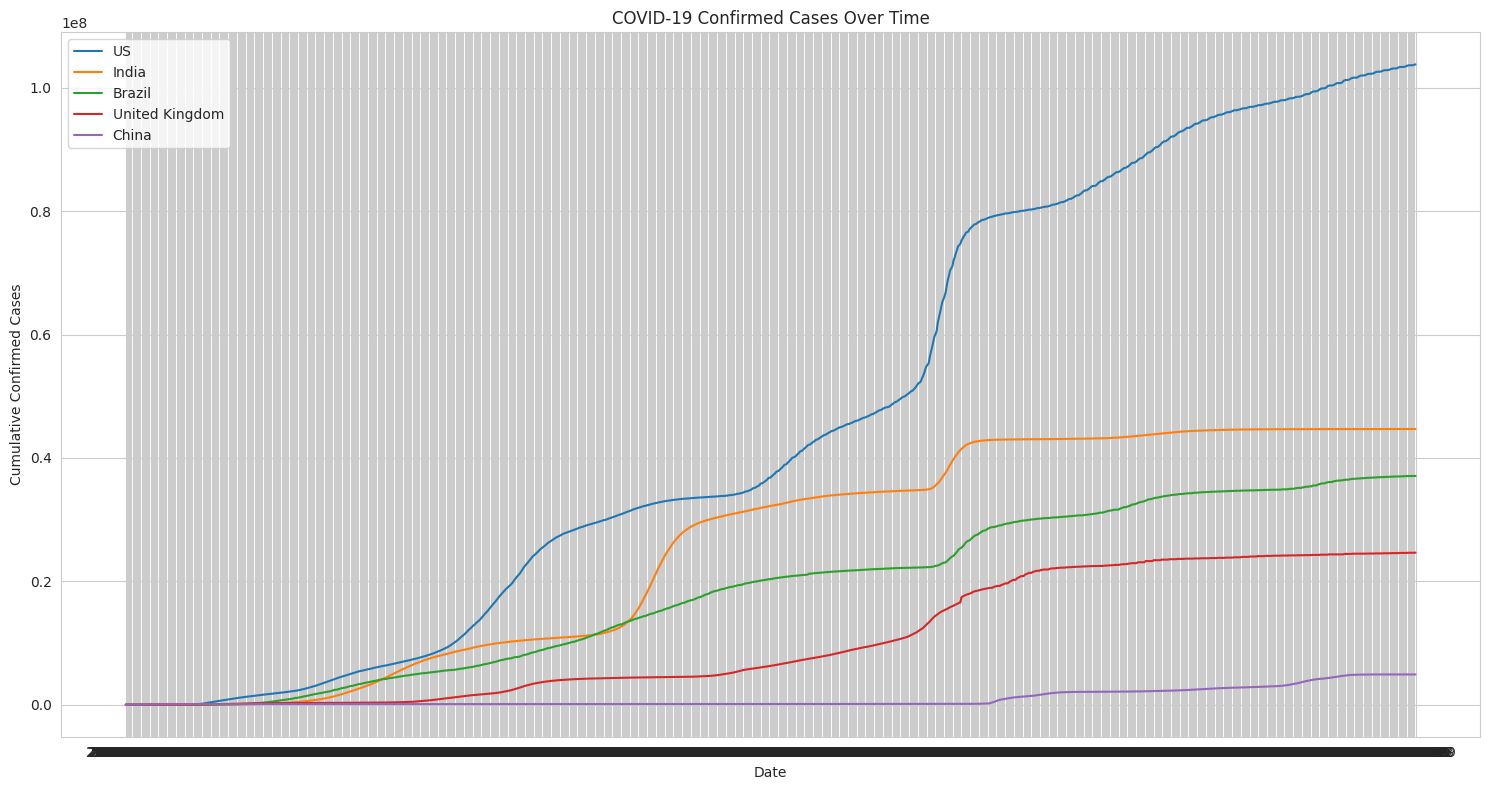

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned data from the previous step
df = pd.read_csv('covid19_cleaned_data.csv')

# --- Bar Graph for Comparison ---
# Use a bar graph to compare the total number of confirmed cases for a few countries.
print("Generating Bar Graph...")

# Get the most recent data for a few selected countries
countries_to_compare = ['US', 'India', 'Brazil', 'United Kingdom', 'China']
df_bar = df[df['Country/Region'].isin(countries_to_compare)].copy()
df_bar = df_bar.groupby('Country/Region')['Confirmed_Cases'].max().reset_index()

plt.figure(figsize=(12, 8))
sns.barplot(x='Confirmed_Cases', y='Country/Region', data=df_bar, palette='viridis')
plt.title('Total Confirmed Cases by Country')
plt.xlabel('Total Confirmed Cases')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

# --- Histogram for Distribution ---
# Use a histogram to show the distribution of daily confirmed cases.
# This helps to detect skewness in the data.
print("\nGenerating Histogram...")
plt.figure(figsize=(10, 6))
# We'll use the final daily totals from each country to avoid a huge spike at 0
df_hist = df.groupby('Country/Region')['Confirmed_Cases'].max().reset_index()
sns.histplot(df_hist['Confirmed_Cases'], kde=True, bins=50)
plt.title('Distribution of Total Confirmed Cases Across Countries')
plt.xlabel('Total Confirmed Cases')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# --- Boxplot for Outlier Detection ---
# A boxplot is excellent for visualizing the distribution of a variable
# and identifying outliers.
print("\nGenerating Boxplot...")
plt.figure(figsize=(10, 6))
sns.boxplot(x=df_hist['Confirmed_Cases'])
plt.title('Box Plot of Total Confirmed Cases Across Countries')
plt.xlabel('Total Confirmed Cases')
plt.tight_layout()
plt.show()

# --- Time-series Plot (as a bonus) ---
# A line plot is the best way to visualize the growth curves you mentioned in your tasks.
print("\nGenerating Time-series Plot...")
plt.figure(figsize=(15, 8))
for country in countries_to_compare:
    country_data = df[df['Country/Region'] == country]
    sns.lineplot(x='Date', y='Confirmed_Cases', data=country_data, label=country)

plt.title('COVID-19 Confirmed Cases Over Time')
plt.xlabel('Date')
plt.ylabel('Cumulative Confirmed Cases')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()